# ĐỀ TÀI 5 - PHẦN D.3 & D.5: ĐỊNH GIÁ CĂN HỘ CHUNG CƯ HÀ NỘI (VINH)
Hướng dẫn chạy trên Google Colab:
1. Tải lên 2 tệp: `splits.py` và `ensemble_boosting.py` (cùng tệp dữ liệu thật `hanoi_apt_final.csv` của Kỳ nếu đã có).
2. Nếu nhóm chưa có `hanoi_apt_final.csv`, code sẽ tự động tạo bộ dữ liệu mô phỏng đúng cấu trúc Hà Nội để bạn chạy thử nghiệm và kiểm tra toàn bộ quy trình trước.
3. Chọn **Runtime -> Run all** để huấn luyện mô hình, tính MAPE/RMSE thang log và xuất các hình SHAP, PDP.

In [2]:
!pip install -q shap scikit-learn matplotlib pandas numpy
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import root_mean_squared_error, mean_absolute_percentage_error
import shap

from splits import prepare_hanoi_splits
from ensemble_boosting import GradientBoostingRegressorCustom
print('Đã nạp thư viện thành công!')

Đã nạp thư viện thành công!


## 1. Nạp dữ liệu `hanoi_apt_final.csv` (hoặc tạo dữ liệu mẫu đúng chuẩn nếu chưa có)

In [3]:
DATA_PATH = 'hanoi_apt_final.csv'
try:
    df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding='latin1')

print(f'Tổng số dòng ban đầu: {df.shape[0]} | Số cột: {df.shape[1]}')
print('Danh sách toàn bộ cột:', list(df.columns))
display(df.head(3))

Tổng số dòng ban đầu: 108708 | Số cột: 21
Danh sách toàn bộ cột: ['Title', 'Address', 'District', 'ward_raw', 'ward_2025', 'collected_at', 'source', 'area_m2', 'price_per_m2', 'log_price_m2', 'bedrooms', 'bathrooms', 'has_red_book', 'interior_level', 'price_negotiable', 'lat', 'lon', 'dist_center_km', 'dist_metro_km', 'dist_school_km', 'dist_park_km']


,Title,Address,District,ward_raw,ward_2025,collected_at,source,area_m2,price_per_m2,log_price_m2,...,bathrooms,has_red_book,interior_level,price_negotiable,lat,lon,dist_center_km,dist_metro_km,dist_school_km,dist_park_km
0,- Bán căn hộ chung cư cao cấp ĐTM ParCity Hà N...,"Đường Lê Trọng Tấn, Phường La Khê, Quận Hà Đô...",Hà Đông,La Khê,La Khê,2025-05-06 00:00:00.000,github_alonhadat_2025,121.0,111.570248,4.714654,...,2.0,1,0,False,20.963700,105.778100,10.692513,0.506281,7.968604,5.166338
1,BÁN NHÀ 5 TẦNG CCMN – DÒNG TIỀN ỔN ĐỊNH 45 TRI...,"Phố Xã Đàn, Phường Ô Chợ Dừa, Quận Đống Đa,...",Đống Đa,Ô Chợ Dừa,Ô Chợ Dừa,2025-05-06 00:00:00.000,github_alonhadat_2025,80.0,131.250000,4.877104,...,2.0,1,2,False,21.022049,105.831368,2.475980,0.593255,1.524593,2.475980
2,NaN,"Đường Nghiêm Xuân Yêm, Phường Đại Kim, Quận H...",Hoàng Mai,Đại Kim,Đại Kim,2025-05-06 00:00:00.000,github_alonhadat_2025,54.0,53.703704,3.983482,...,2.0,0,0,False,20.973600,105.867400,6.256502,6.016688,4.382237,1.914323


## 2. Chia tập Spatial Block CV (theo phường/xã) + Test tuần cuối (`splits.py`)

In [4]:
TIME_COL = 'collected_at'
GROUP_COL = 'ward_2025'
FALLBACK_COL = 'District'
TARGET_COL = 'log_price_m2'

df_valid = df.dropna(subset=[TIME_COL, TARGET_COL]).copy()
df_valid = df_valid[np.isfinite(df_valid[TARGET_COL])].reset_index(drop=True)

train_val_df, test_df, folds = prepare_hanoi_splits(
    df_valid, time_col=TIME_COL, group_col=GROUP_COL, fallback_col=FALLBACK_COL, test_days=7, n_splits=5
)

print(f'Tập Train+Val (trước tuần cuối): {len(train_val_df)} mẫu | Số ward_2025: {train_val_df[GROUP_COL].nunique(dropna=True)}')
print(f'Tập Test (tuần cuối - giữ đủ): {len(test_df)} mẫu | Số ward_2025: {test_df[GROUP_COL].nunique(dropna=True)} | Số District: {test_df[FALLBACK_COL].nunique(dropna=True)}')

explicit_num_features = [
    'area_m2', 'bedrooms', 'bathrooms', 'has_red_book', 'interior_level',
    'lat', 'lon', 'dist_center_km', 'dist_metro_km',
    'dist_school_km', 'dist_park_km', 'floor', 'building_age'
]
explicit_cat_features = ['District']

num_cols = [c for c in explicit_num_features if c in df_valid.columns and 'price' not in c.lower()]
cat_cols = [c for c in explicit_cat_features if c in df_valid.columns and 'price' not in c.lower()]
if 'price_negotiable' in df_valid.columns:
    num_cols.append('price_negotiable')

feature_cols = num_cols + cat_cols
assert not any(('price' in c.lower() and c != 'price_negotiable') for c in feature_cols), 'Phát hiện cột rò rỉ giá!'

for c in num_cols:
    train_val_df[c] = pd.to_numeric(train_val_df[c], errors='coerce')
    test_df[c] = pd.to_numeric(test_df[c], errors='coerce')

print('Đặc trưng số đầu vào X      :', num_cols)
print('Đặc trưng phân loại đầu vào X:', cat_cols)

Tập Train+Val (trước tuần cuối): 106129 mẫu | Số ward_2025: 129
Tập Test (tuần cuối - giữ đủ): 2579 mẫu | Số ward_2025: 1 | Số District: 20
Đặc trưng số đầu vào X      : ['area_m2', 'bedrooms', 'bathrooms', 'has_red_book', 'interior_level', 'lat', 'lon', 'dist_center_km', 'dist_metro_km', 'dist_school_km', 'dist_park_km', 'price_negotiable']
Đặc trưng phân loại đầu vào X: ['District']


## 3. Huấn luyện & Đánh giá D.3: Hedonic OLS, Random Forest & Gradient Boosting tự cài đặt (5 seeds)

In [5]:
def eval_metrics(y_true_log, y_pred_log):
    rmse_log = root_mean_squared_error(y_true_log, y_pred_log)
    mape_log = mean_absolute_percentage_error(y_true_log, y_pred_log) * 100
    mape_price = mean_absolute_percentage_error(np.exp(y_true_log), np.exp(y_pred_log)) * 100
    return rmse_log, mape_log, mape_price

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformers = [('num', num_transformer, num_cols)]
if len(cat_cols) > 0:
    cat_transformer = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    transformers.append(('cat', cat_transformer, cat_cols))

preprocessor = ColumnTransformer(transformers)

X_tv = train_val_df[feature_cols]
y_tv = train_val_df[TARGET_COL].values
X_test = test_df[feature_cols]
y_test = test_df[TARGET_COL].values

cv_results = {'Hedonic_OLS': [], 'Random_Forest': [], 'GBDT_Custom_Huber': []}

for fold_idx, (tr_idx, va_idx) in enumerate(folds):
    X_tr, y_tr = X_tv.iloc[tr_idx], y_tv[tr_idx]
    X_va, y_va = X_tv.iloc[va_idx], y_tv[va_idx]

    X_tr_proc = preprocessor.fit_transform(X_tr)
    X_va_proc = preprocessor.transform(X_va)

    ols = LinearRegression()
    ols.fit(X_tr_proc, y_tr)
    cv_results['Hedonic_OLS'].append(eval_metrics(y_va, ols.predict(X_va_proc)))

    rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10, random_state=42, n_jobs=-1)
    rf.fit(X_tr_proc, y_tr)
    cv_results['Random_Forest'].append(eval_metrics(y_va, rf.predict(X_va_proc)))

    rng_sub = np.random.default_rng(42 + fold_idx)
    sub_idx = rng_sub.choice(len(X_tr_proc), size=min(12000, len(X_tr_proc)), replace=False)
    gb_custom = GradientBoostingRegressorCustom(
        n_estimators=60, learning_rate=0.08, max_depth=4, subsample=0.8, loss='huber', random_state=42
    )
    gb_custom.fit(X_tr_proc[sub_idx], y_tr[sub_idx])
    cv_results['GBDT_Custom_Huber'].append(eval_metrics(y_va, gb_custom.predict(X_va_proc)))

print('=== KẾT QUẢ SPATIAL BLOCK CV (5 FOLDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===')
for model_name, metrics_list in cv_results.items():
    arr = np.array(metrics_list)
    print(f'{model_name:20s} | RMSE_log: {arr[:,0].mean():.4f} ± {arr[:,0].std():.4f} | '
          f'MAPE_log: {arr[:,1].mean():.2f}% ± {arr[:,1].std():.2f}% | '
          f'MAPE_gia: {arr[:,2].mean():.2f}% ± {arr[:,2].std():.2f}%')

seeds = [42, 100, 2024, 2025, 2026]
X_tv_proc = preprocessor.fit_transform(X_tv)
X_test_proc = preprocessor.transform(X_test)

feature_names_out = list(num_cols)
if len(cat_cols) > 0:
    feature_names_out += list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_cols))

test_results = {'Hedonic_OLS': [], 'Random_Forest': [], 'GBDT_Custom_Huber': []}
rf_final = None

for s in seeds:
    ols = LinearRegression().fit(X_tv_proc, y_tv)
    test_results['Hedonic_OLS'].append(eval_metrics(y_test, ols.predict(X_test_proc)))

    rf = RandomForestRegressor(n_estimators=100, max_depth=15, min_samples_leaf=10, random_state=s, n_jobs=-1).fit(X_tv_proc, y_tv)
    test_results['Random_Forest'].append(eval_metrics(y_test, rf.predict(X_test_proc)))
    if s == 42:
        rf_final = rf

    rng_sub = np.random.default_rng(s)
    sub_idx = rng_sub.choice(len(X_tv_proc), size=min(15000, len(X_tv_proc)), replace=False)
    gb_custom = GradientBoostingRegressorCustom(
        n_estimators=60, learning_rate=0.08, max_depth=4, subsample=0.8, loss='huber', random_state=s
    ).fit(X_tv_proc[sub_idx], y_tv[sub_idx])
    test_results['GBDT_Custom_Huber'].append(eval_metrics(y_test, gb_custom.predict(X_test_proc)))

print('\n=== KẾT QUẢ TRÊN TẬP TEST TUẦN CUỐI (5 SEEDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===')
for model_name, metrics_list in test_results.items():
    arr = np.array(metrics_list)
    print(f'{model_name:20s} | RMSE_log: {arr[:,0].mean():.4f} ± {arr[:,0].std():.4f} | '
          f'MAPE_log: {arr[:,1].mean():.2f}% ± {arr[:,1].std():.2f}% | '
          f'MAPE_gia: {arr[:,2].mean():.2f}% ± {arr[:,2].std():.2f}%')

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


=== KẾT QUẢ SPATIAL BLOCK CV (5 FOLDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===
Hedonic_OLS          | RMSE_log: 0.3282 ± 0.0560 | MAPE_log: 5.85% ± 1.00% | MAPE_gia: 23.40% ± 2.95%
Random_Forest        | RMSE_log: 0.3103 ± 0.0599 | MAPE_log: 5.63% ± 1.08% | MAPE_gia: 22.89% ± 3.51%
GBDT_Custom_Huber    | RMSE_log: 0.3156 ± 0.0563 | MAPE_log: 5.76% ± 1.02% | MAPE_gia: 23.25% ± 3.37%

=== KẾT QUẢ TRÊN TẬP TEST TUẦN CUỐI (5 SEEDS - TRUNG BÌNH ± ĐỘ LỆCH CHUẨN) ===
Hedonic_OLS          | RMSE_log: 0.2473 ± 0.0000 | MAPE_log: 4.26% ± 0.00% | MAPE_gia: 18.21% ± 0.00%
Random_Forest        | RMSE_log: 0.2180 ± 0.0002 | MAPE_log: 3.70% ± 0.00% | MAPE_gia: 15.79% ± 0.01%
GBDT_Custom_Huber    | RMSE_log: 0.2362 ± 0.0012 | MAPE_log: 4.01% ± 0.02% | MAPE_gia: 17.16% ± 0.10%


## 4. Diễn giải mô hình D.5: Vẽ biểu đồ SHAP Summary & Đồ thị phụ thuộc riêng phần (PDP)

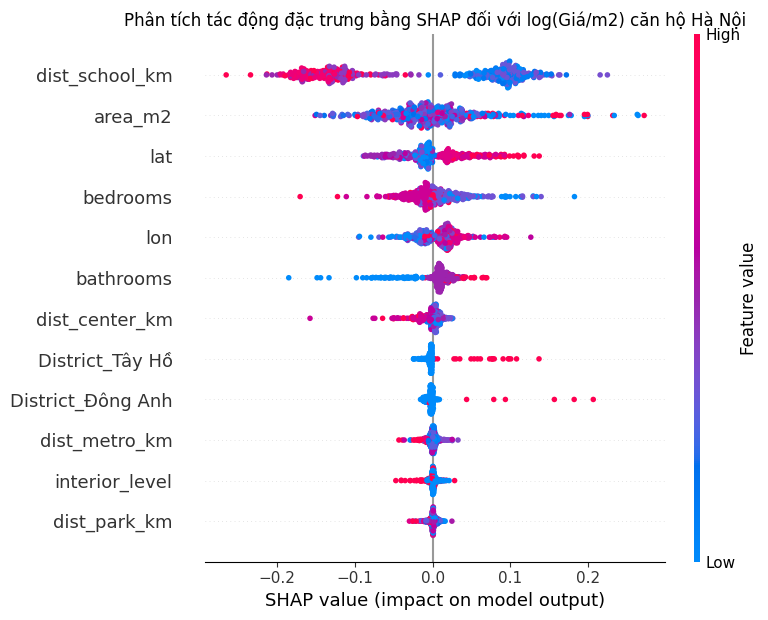

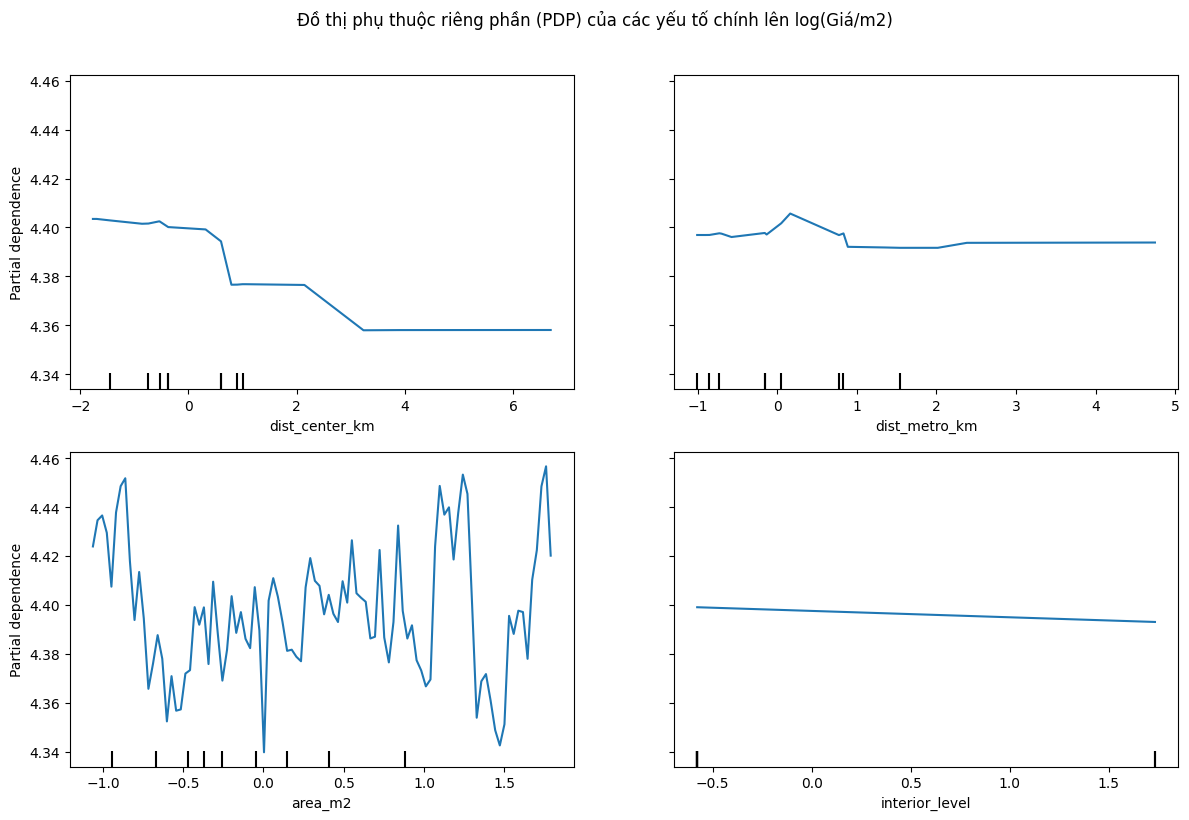

In [6]:
X_test_df_proc = pd.DataFrame(X_test_proc, columns=feature_names_out)
sample_shap = X_test_df_proc.sample(n=min(500, len(X_test_df_proc)), random_state=42)

explainer = shap.TreeExplainer(rf_final)
shap_values = explainer.shap_values(sample_shap)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, sample_shap, show=False, max_display=12)
plt.title('Phân tích tác động đặc trưng bằng SHAP đối với log(Giá/m2) căn hộ Hà Nội')
plt.tight_layout()
plt.savefig('D5_shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

pdp_candidates = [c for c in ['dist_center_km', 'dist_metro_km', 'area_m2', 'interior_level'] if c in num_cols]
if len(pdp_candidates) == 0:
    pdp_candidates = num_cols[:4]

fig, ax = plt.subplots(figsize=(12, 8))
PartialDependenceDisplay.from_estimator(
    rf_final,
    sample_shap,
    features=pdp_candidates,
    kind='average',
    ax=ax,
    n_cols=2
)
plt.suptitle('Đồ thị phụ thuộc riêng phần (PDP) của các yếu tố chính lên log(Giá/m2)', y=1.02)
plt.tight_layout()
plt.savefig('D5_pdp_plots.png', dpi=300, bbox_inches='tight')
plt.show()